In [2]:
import pandas as pd
import numpy as np
import sys

sys.path.append("../src")

import clean
import features

data_folder = "../data/cleaned/"

names = ["orders", "order_items", "customers", "restaurants", "menu",
         "delivery_partners", "payments", "customer_feedback",
         "promotions", "cities", "traffic", "weather"]

tables = {}
clean_tables = {}

for n in names:
    tables[n] = pd.read_csv(data_folder + n + ".csv")
    clean_tables[n] = getattr(clean, "clean_" + n)(tables[n])

abt = clean.build_abt(clean_tables)
abt = features.build_features(abt)

print("ABT shape:", abt.shape)

ABT shape: (20475, 68)


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print([c for c in abt.columns if 'churn' in c.lower()], "<- columns with 'churn' in the name")
print()
print(abt['CustomerID'].nunique(), "different customers placed orders")
print()
print("Orders per customer:")
print(abt.groupby('CustomerID').size().describe())
print()
dates = pd.to_datetime(abt['OrderDate'])
print("First order:", dates.min(), " Last order:", dates.max())

[] <- columns with 'churn' in the name

9827 different customers placed orders

Orders per customer:
count    9827.000000
mean        2.083545
std         1.134296
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         8.000000
dtype: float64

First order: 2023-01-01 00:00:00  Last order: 2024-12-31 00:00:00


In [4]:
orders = abt[['CustomerID', 'OrderDate']].copy()
orders['OrderDate'] = pd.to_datetime(orders['OrderDate'])
last_date = orders['OrderDate'].max()

for window in [90, 180, 270]:
    cutoff = last_date - pd.Timedelta(days=window)
    before = set(orders[orders['OrderDate'] <= cutoff]['CustomerID'])
    after = set(orders[orders['OrderDate'] > cutoff]['CustomerID'])
    churned = before - after

    print("Window:", window, "days | Cutoff:", cutoff.date())
    print("  Customers active before cutoff:", len(before))
    print("  Churned (no order after cutoff):", len(churned))
    print("  Churn rate:", round(len(churned) / len(before) * 100, 1), "%")
    print()

Window: 90 days | Cutoff: 2024-10-02
  Customers active before cutoff: 9315
  Churned (no order after cutoff): 7552
  Churn rate: 81.1 %

Window: 180 days | Cutoff: 2024-07-04
  Customers active before cutoff: 8668
  Churned (no order after cutoff): 5718
  Churn rate: 66.0 %

Window: 270 days | Cutoff: 2024-04-05
  Customers active before cutoff: 7915
  Churned (no order after cutoff): 4266
  Churn rate: 53.9 %



In [5]:
abt['OrderDate'] = pd.to_datetime(abt['OrderDate'])
abt['IsCancelled'] = (abt['OrderStatus'] == 'Cancelled').astype(int)
abt['IsLate'] = (abt['OrderStatus'] == 'Delivered Late').astype(int)

cutoff = abt['OrderDate'].max() - pd.Timedelta(days=270)
past = abt[abt['OrderDate'] <= cutoff]
future = abt[abt['OrderDate'] > cutoff]

cust = past.groupby('CustomerID').agg(
    NumOrders=('OrderID', 'count'),
    TotalSpent=('FinalAmount', 'sum'),
    AvgOrderValue=('FinalAmount', 'mean'),
    CancelRate=('IsCancelled', 'mean'),
    LateRate=('IsLate', 'mean'),
    AvgDeliveryTime=('DeliveryTimeMinutes', 'mean'),
    AvgRating=('CustomerRating', 'mean'),
    FirstOrder=('OrderDate', 'min'),
    LastOrder=('OrderDate', 'max'),
    CustomerAge=('CustomerAge', 'first'),
    CustomerGender=('CustomerGender', 'first'),
    Membership=('Membership', 'first'),
    CustomerCity=('CustomerCity', 'first'),
    PreferredCuisine=('PreferredCuisine', 'first')
).reset_index()

cust['DaysSinceLastOrder'] = (cutoff - cust['LastOrder']).dt.days
cust['DaysSinceFirstOrder'] = (cutoff - cust['FirstOrder']).dt.days
cust['Churned'] = (~cust['CustomerID'].isin(future['CustomerID'])).astype(int)
cust = cust.drop(columns=['FirstOrder', 'LastOrder'])

print("Customer table:", cust.shape)
print(cust['Churned'].value_counts())
print("Churn rate:", round(cust['Churned'].mean() * 100, 1), "%")
print()
print(cust.head())

Customer table: (7915, 16)
Churned
1    4266
0    3649
Name: count, dtype: int64
Churn rate: 53.9 %

   CustomerID  NumOrders  TotalSpent  AvgOrderValue  CancelRate  LateRate  \
0           1          1      744.50       744.5000        1.00       0.0   
1           2          2      810.95       405.4750        0.00       0.0   
2           6          2      873.45       436.7250        0.50       0.0   
3           7          1      664.75       664.7500        1.00       0.0   
4          11          4     1742.75       435.6875        0.75       0.0   

   AvgDeliveryTime  AvgRating  CustomerAge CustomerGender  Membership  \
0        14.000000        NaN         35.0           Male       Basic   
1        31.500000        5.0         29.0           Male  Zomato Pro   
2        35.000000        2.0         26.0          Other       Basic   
3        37.000000        NaN         28.0         Female       Basic   
4        34.666667        2.0         36.0          Other       Basic  

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

num_features = ['NumOrders', 'TotalSpent', 'AvgOrderValue', 'CancelRate', 'LateRate',
                'AvgDeliveryTime', 'AvgRating', 'CustomerAge',
                'DaysSinceLastOrder', 'DaysSinceFirstOrder']
cat_features = ['CustomerGender', 'Membership', 'CustomerCity', 'PreferredCuisine']

X = cust[num_features + cat_features]
y = cust['Churned']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocessor = ColumnTransformer([
    ('num', Pipeline([('fill', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num_features),
    ('cat', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_features)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)
print("Train:", X_train_ready.shape, " Test:", X_test_ready.shape)

models = {
    'Baseline (all churned)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8,
                                            min_samples_leaf=20, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train_ready, y_train)
    pred = model.predict(X_test_ready)
    prob_test = model.predict_proba(X_test_ready)[:, 1]
    prob_train = model.predict_proba(X_train_ready)[:, 1]
    results.append([name,
                    accuracy_score(y_test, pred),
                    precision_score(y_test, pred, zero_division=0),
                    recall_score(y_test, pred, zero_division=0),
                    f1_score(y_test, pred, zero_division=0),
                    roc_auc_score(y_test, prob_test),
                    roc_auc_score(y_train, prob_train)])

churn_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision',
                                               'Recall', 'F1', 'AUC_test', 'AUC_train'])
print(churn_results.round(3))

Train: (6332, 55)  Test: (1583, 55)
                    Model  Accuracy  Precision  Recall     F1  AUC_test  \
0  Baseline (all churned)     0.539      0.539   1.000  0.700     0.500   
1     Logistic Regression     0.524      0.539   0.803  0.645     0.507   
2           Decision Tree     0.531      0.536   0.968  0.690     0.494   
3           Random Forest     0.536      0.539   0.954  0.689     0.503   
4       Gradient Boosting     0.536      0.546   0.822  0.656     0.504   

   AUC_train  
0      0.500  
1      0.555  
2      0.545  
3      0.739  
4      0.734  


In [7]:
print(cust.groupby('Churned')[num_features].mean().round(2).T)
print()

from sklearn.model_selection import RandomizedSearchCV

lr_params = {'C': [0.001, 0.01, 0.1, 1, 10]}
rf_params = {'n_estimators': [100, 200], 'max_depth': [3, 5, 8],
             'min_samples_leaf': [20, 50, 100]}
gb_params = {'n_estimators': [50, 100, 200], 'max_depth': [2, 3, 4],
             'learning_rate': [0.01, 0.05, 0.1], 'min_samples_leaf': [20, 50, 100]}

tuned_churn = {}

for name, model, params, n in [
    ('Logistic Regression (tuned)', LogisticRegression(max_iter=1000), lr_params, 5),
    ('Random Forest (tuned)', RandomForestClassifier(random_state=42, n_jobs=-1), rf_params, 8),
    ('Gradient Boosting (tuned)', GradientBoostingClassifier(random_state=42), gb_params, 8)
]:
    search = RandomizedSearchCV(model, params, n_iter=n, cv=3,
                                scoring='roc_auc', random_state=42)
    search.fit(X_train_ready, y_train)
    pred = search.predict(X_test_ready)
    prob = search.predict_proba(X_test_ready)[:, 1]
    print(name)
    print("  Best settings:", search.best_params_)
    print("  Test accuracy:", round(accuracy_score(y_test, pred), 3))
    print("  Test AUC     :", round(roc_auc_score(y_test, prob), 3))
    tuned_churn[name] = search

Churned                   0       1
NumOrders              1.65    1.64
TotalSpent           644.99  646.41
AvgOrderValue        390.06  394.28
CancelRate             0.22    0.22
LateRate               0.10    0.10
AvgDeliveryTime       36.90   36.58
AvgRating              3.57    3.60
CustomerAge           30.57   30.91
DaysSinceLastOrder   189.99  188.42
DaysSinceFirstOrder  272.61  271.35

Logistic Regression (tuned)
  Best settings: {'C': 0.1}
  Test accuracy: 0.525
  Test AUC     : 0.506
Random Forest (tuned)
  Best settings: {'n_estimators': 100, 'min_samples_leaf': 100, 'max_depth': 8}
  Test accuracy: 0.538
  Test AUC     : 0.496
Gradient Boosting (tuned)
  Best settings: {'n_estimators': 100, 'min_samples_leaf': 100, 'max_depth': 3, 'learning_rate': 0.1}
  Test accuracy: 0.525
  Test AUC     : 0.488


                         Model  Accuracy  Precision  Recall     F1  AUC_test  \
1          Logistic Regression     0.524      0.539   0.803  0.645     0.507   
5  Logistic Regression (tuned)     0.525      0.539   0.821  0.651     0.506   
4            Gradient Boosting     0.536      0.546   0.822  0.656     0.504   
3                Random Forest     0.536      0.539   0.954  0.689     0.503   
0       Baseline (all churned)     0.539      0.539   1.000  0.700     0.500   
6        Random Forest (tuned)     0.538      0.538   0.993  0.698     0.496   
2                Decision Tree     0.531      0.536   0.968  0.690     0.494   
7    Gradient Boosting (tuned)     0.525      0.541   0.777  0.638     0.488   

   AUC_train  
1      0.555  
5      0.555  
4      0.734  
3      0.739  
0      0.500  
6      0.636  
2      0.545  
7      0.678  


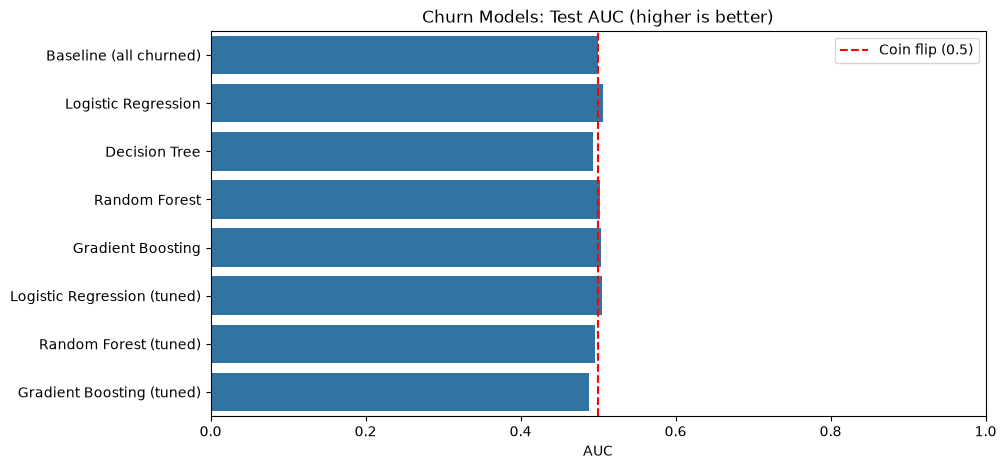

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

tuned_rows = []
for name, search in tuned_churn.items():
    pred = search.predict(X_test_ready)
    prob_test = search.predict_proba(X_test_ready)[:, 1]
    prob_train = search.predict_proba(X_train_ready)[:, 1]
    tuned_rows.append([name,
                       accuracy_score(y_test, pred),
                       precision_score(y_test, pred, zero_division=0),
                       recall_score(y_test, pred, zero_division=0),
                       f1_score(y_test, pred, zero_division=0),
                       roc_auc_score(y_test, prob_test),
                       roc_auc_score(y_train, prob_train)])

final_churn = pd.concat([churn_results, pd.DataFrame(tuned_rows, columns=churn_results.columns)],
                        ignore_index=True)
print(final_churn.sort_values('AUC_test', ascending=False).round(3))

final_churn.to_csv('../reports/churn_model_comparison.csv', index=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=final_churn['AUC_test'], y=final_churn['Model'])
plt.axvline(0.5, color='red', linestyle='--', label='Coin flip (0.5)')
plt.xlim(0, 1)
plt.title('Churn Models: Test AUC (higher is better)')
plt.xlabel('AUC')
plt.ylabel('')
plt.legend()
plt.show()

Accuracy: 0.525
AUC     : 0.506

Confusion matrix (rows = actual, columns = predicted):
[[131 599]
 [153 700]]

Top 10 columns by importance:
CustomerCity           0.0077
AvgOrderValue          0.0076
AvgDeliveryTime        0.0062
PreferredCuisine       0.0058
AvgRating              0.0020
CancelRate            -0.0002
DaysSinceFirstOrder   -0.0002
CustomerAge           -0.0012
DaysSinceLastOrder    -0.0020
NumOrders             -0.0021
dtype: float64


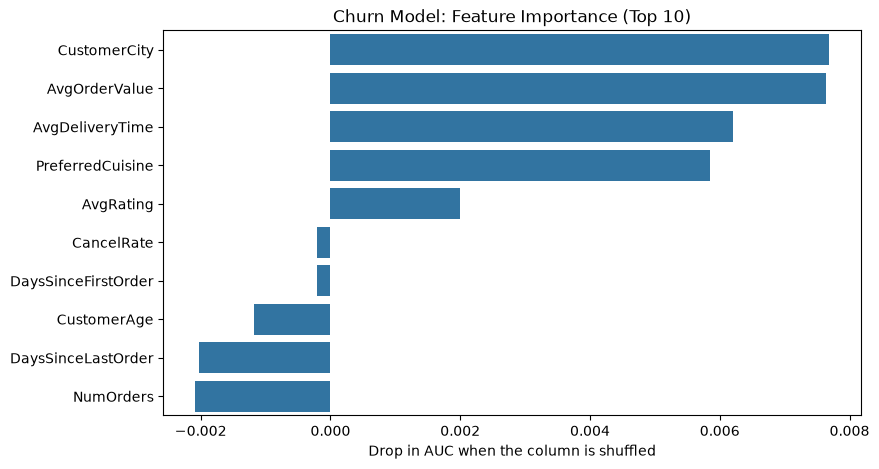

Model saved to models/churn_best_model.pkl


In [9]:
import joblib
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix

final_churn_model = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(C=0.1, max_iter=1000))
])
final_churn_model.fit(X_train, y_train)

pred = final_churn_model.predict(X_test)
prob = final_churn_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("AUC     :", round(roc_auc_score(y_test, prob), 3))
print()
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, pred))
print()

perm = permutation_importance(final_churn_model, X_test, y_test, n_repeats=5,
                              random_state=42, scoring='roc_auc')
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("Top 10 columns by importance:")
print(imp.head(10).round(4))

plt.figure(figsize=(9, 5))
sns.barplot(x=imp.head(10).values, y=imp.head(10).index)
plt.title('Churn Model: Feature Importance (Top 10)')
plt.xlabel('Drop in AUC when the column is shuffled')
plt.ylabel('')
plt.show()

joblib.dump(final_churn_model, '../models/churn_best_model.pkl')
print("Model saved to models/churn_best_model.pkl")

In [10]:
import os
print(os.listdir('../models'))

['churn_best_model.pkl', 'delivery_time_best_model.pkl']


In [11]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

OUT = '../powerbi/data/'
os.makedirs(OUT, exist_ok=True)

prob = final_churn_model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)

risk = np.where(prob >= 0.6, 'High', np.where(prob >= 0.4, 'Medium', 'Low'))
scores = pd.DataFrame({
    'CustomerID': cust.loc[X_test.index, 'CustomerID'].values,
    'ChurnProbability': prob,
    'ActualChurn': np.array(y_test),
    'RiskSegment': risk
})
scores.to_csv(OUT + 'churn_scores.csv', index=False)

drivers = imp.reset_index()
drivers.columns = ['Feature', 'Importance']
drivers.to_csv(OUT + 'churn_drivers.csv', index=False)

metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Value': [accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0),
              recall_score(y_test, pred, zero_division=0), f1_score(y_test, pred, zero_division=0),
              roc_auc_score(y_test, prob)]
})
metrics.to_csv(OUT + 'churn_metrics.csv', index=False)

print(scores.shape)
print(scores['RiskSegment'].value_counts())
print(metrics.round(3))
print(os.listdir(OUT))

(1583, 4)
RiskSegment
Medium    1476
High       105
Low          2
Name: count, dtype: int64
      Metric  Value
0   Accuracy  0.525
1  Precision  0.539
2     Recall  0.821
3         F1  0.651
4    ROC-AUC  0.506
['churn_drivers.csv', 'churn_metrics.csv', 'churn_scores.csv', 'delivery_feature_importance.csv', 'delivery_metrics.csv', 'delivery_predictions.csv']


In [1]:
import pandas as pd

scores = pd.read_csv('../powerbi/data/churn_scores.csv')
scores['RiskSegment'] = pd.qcut(scores['ChurnProbability'].rank(method='first'), 3,
                                labels=['Low', 'Medium', 'High'])
scores.to_csv('../powerbi/data/churn_scores.csv', index=False)
print(scores['RiskSegment'].value_counts())

RiskSegment
Low       528
High      528
Medium    527
Name: count, dtype: int64
